# Pattern Matching

## Imports

In [26]:
import os
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt

## Directories

In [27]:
base_dir = os.getcwd()
processed_data_dir = os.path.join(base_dir, 'processed_data')
results_dir = os.path.join(base_dir, 'results')

## Load Data

In [28]:
processed_data_filepath = os.path.join(base_dir, 'processed_data', 'ampds_dataset.npz')
processed_data = np.load(processed_data_filepath)

# Check Data
print(f'Processed Data Items: {processed_data.files}')

Processed Data Items: ['electrical_quantities', 'appliance_names', 'agg_norm', 'apps_norm', 'apps_min', 'apps_max', 'apps_mean', 'apps_median', 'apps_std', 'apps_on_threshold', 'apps_on_percentrage', 'train_indices', 'val_indices', 'test_indices', 'train_val_test_split', 'T', 'window_length', 'stride']


In [37]:
# Unpack-data
appliance_names = processed_data['appliance_names']
apps_column_names = ['time', 'id'] + list(appliance_names)

window_length = processed_data['window_length']
agg_norm = processed_data['agg_norm']
apps_norm = processed_data['apps_norm']
train_indices = processed_data['train_indices']
val_indices = processed_data['val_indices']
test_indices = processed_data['test_indices']

### Load Distance Metrics

We previously calculate three distance metrics for each `(template, query)` pair of windows. A `template` consists of a window from the training set and a `query` consists of a window from the validation or testing set. We saved the results in a lookup dictionary. Each key is a `(template_idx, query_idx)` tuple, and its value is a `metrics` dictionary containing the `feature_distance`, `pearson_correlation`, and `dtw_distance`. We load the lookup table and display a preview of its contents as a table.

In [30]:
distance_metrics_filepath = os.path.join(results_dir, 'combined_metric_lookup.pkl')
combined_metric_lookup = pd.read_pickle(distance_metrics_filepath)

In [31]:
combined_lookup_df = pd.DataFrame(
    [
        {
            "template idx": template_idx,
            "query idx": query_idx,
            "feature_distance": metrics["feature_distance"],
            "pearson_correlation": metrics["pearson_correlation"],
            "dtw_distance": metrics["dtw_distance"],
        } for (template_idx, query_idx), metrics in combined_metric_lookup.items()])

display(combined_lookup_df.head().style.set_caption('Consolidated Distance Metrics').hide(axis='index'))

template idx,query idx,feature_distance,pearson_correlation,dtw_distance
500,277,2.903394,0.270804,11.780360
851,277,0.330063,0.481780,4.230345
559,277,1.656885,0.258226,5.775319
845,277,1.259538,0.778396,2.950938
471,277,2.274879,0.784573,4.254507


## Predict Appliance Profiles

Our pattern-matching NILM algorithm predicts appliance-level usage from aggregate power measurements. It does this by extracting time-series frames of aggregate power consumption and comparing them against various aggregate consumption templates. Once the best-matching template is identified, the algorithm assigns its associated appliance-level usage.

The `predict_frame` function selects the best-matching template for a given query window and returns its corresponding appliance power predictions. First, we define `metric_directions` to indicate whether each metric corresponds to a maximization or minimization problem. Then, we identify candidate templates. The `combined_metric_lookup` dictionary contains matching metrics associated with template/query index pais. The list comprehension iterates through every template/query pair, keeps only entries corresponding to the requested `query_idx`, and extracts the template index and the selected metric value. Using the `min()` function, we select the best template. Using the best template starting index, we extract and return the appliance prediction window.

In [45]:
def predict_frame(apps_norm, query_idx, window_length, combined_metric_lookup, method):

    metric_directions = {
        'feature_distance': 1,
        'pearson_correlation': -1,
        'dtw_distance': 1}

    candidates = [
        (template_idx, metrics[method])
        for (template_idx, candidate_query_idx), metrics
        in combined_metric_lookup.items()
        if candidate_query_idx == query_idx]

    direction = metric_directions[method]
    best_template_idx = min(candidates, key=lambda x: direction * x[1])[0]
    return apps_norm[best_template_idx : best_template_idx + window_length]

The `predict_time_series()` function reconstructs a continous appliance power time series by combining predictions from multiple overlapping query windows. First, we determine the earliest and latest indices covered by the query windows. Next, we initialize two arrays. `totals` accumulates appliance power predictions at each time index. `counts` tracks how many predictions exist for each time index. Next, we generate predictions for each query window by passing the query index to `predict_frame()`, which returns the corresponding appliance predictions. We determine which portions of the prediction fall within the previously defined time range. If the prediction falls entirely outside the defined range, it is skipped. Next we define the `source` and `target` slices which map the overlapping potion of the prediction to its corresponding location in the output arrays. `source` corresponds to positions within the individual predition window. `target` corresponds to positions within the reconstructed time series. We accumulate predictions and average overlapping predictions. We returnt the reconstructed time series.

In [46]:
def predict_time_series(apps_norm, query_indices, window_length, combined_metric_lookup, method):

    start = max(0, min(query_indices))
    end = min(len(apps_norm), max(query_indices) + window_length)

    n_appliances = apps_norm.shape[1] - 2 # exclude 'id' and 'time' columns.
    n_samples = end - start

    totals = np.zeros((n_samples, n_appliances), dtype=float)
    counts = np.zeros(n_samples, dtype=int)

    for query_idx in query_indices:
        prediction = predict_frame(apps_norm, query_idx, window_length, combined_metric_lookup, method)

        # Determine the overlapping region
        target_start = max(query_idx, start)
        target_end = min(query_idx + len(prediction), end)
        if target_start >= target_end: continue

        # Map the overlapping region to source and target indices
        source = slice(target_start - query_idx, target_end - query_idx)
        target = slice(target_start - start, target_end - start)

        # Accumulate appliance predictions, excluding ID/time columns.
        totals[target] += prediction[source, 2:]
        counts[target] += 1

    # Average predicitons wherever at least one estimate exists
    covered = counts > 0

    result = np.full((n_samples, apps_norm.shape[1]), np.nan)
    result[covered, 2:] = totals[covered] / counts[covered, None]
    result[:, :2] = apps_norm[start:end, :2]

    return result

In [47]:
example_query_indices = val_indices[0:100]
example_apps_time_series = predict_time_series(apps_norm, example_query_indices, window_length, combined_metric_lookup, method='dtw_distance')

example_apps_df = pd.DataFrame(
    example_apps_time_series,
    columns=apps_column_names)

display(example_apps_df.head().style.format('{:.2f}').set_caption('Example Appliance Profile Prediction'))

,time,id,CWE,DWE,FRE,HPE,WOE,CDE,FGE,HTE
0,12120.00,1.00,0.00,0.00,0.79,0.64,0.00,0.00,0.00,0.04
1,12180.00,1.00,0.00,0.00,0.79,0.64,0.00,0.00,0.00,0.04
2,12240.00,1.00,0.00,0.00,0.83,0.64,0.00,0.00,0.00,0.04
3,12300.00,1.00,0.00,0.00,0.48,0.21,0.00,0.00,0.00,0.04
4,12360.00,1.00,0.00,0.00,0.43,0.16,0.00,0.00,0.00,0.04


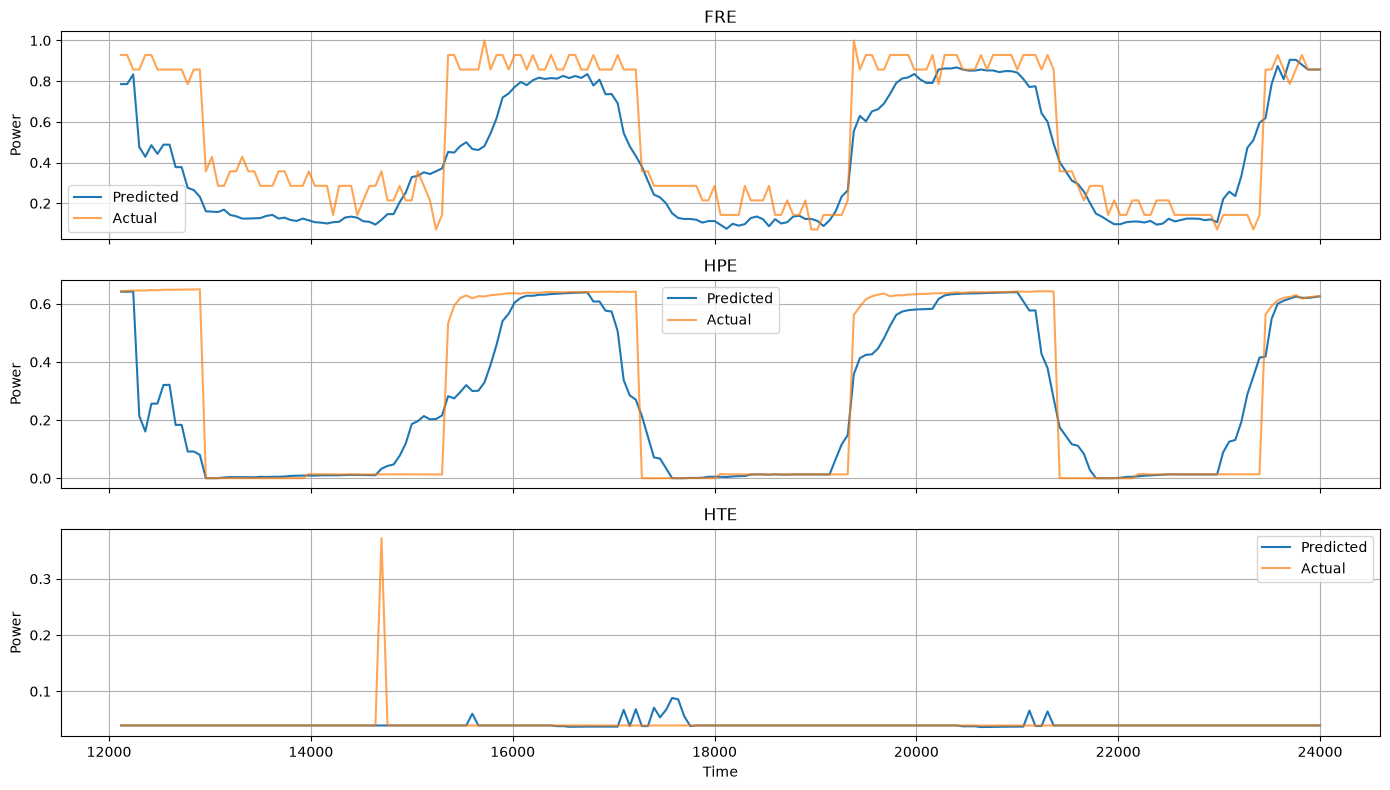

In [48]:
apps_df = pd.DataFrame(apps_norm, columns=apps_column_names)

plot_df = example_apps_df.merge(
    apps_df[['time', 'FRE', 'HPE', 'HTE']],
    on='time',
    how='left',
    suffixes=('_predicted', '_actual')
)

appliances = ['FRE', 'HPE', 'HTE']

fig, axes = plt.subplots(len(appliances), 1, figsize=(14, 8), sharex=True)

for ax, appliance in zip(axes, appliances):
    ax.plot(plot_df['time'], plot_df[f'{appliance}_predicted'], label='Predicted')
    ax.plot(plot_df['time'], plot_df[f'{appliance}_actual'], label='Actual', alpha=0.7)

    ax.set_title(appliance)
    ax.set_ylabel('Power')
    ax.legend()
    ax.grid(True)

axes[-1].set_xlabel('Time')
plt.tight_layout()
plt.show()

As we can see in these results, Dynamic Time Warping (DTW) does a decent job at predicting the appliance power for the appliances with more regular behavior.